<a href="https://colab.research.google.com/github/Burstpian2002/YOLOn26-small-healthcare-datasets/blob/main/New_datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
tfrom google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### evaluation data

In [ ]:
from pathlib import Path
from collections import Counter

labels_dir = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/train/labels"

class_counts = Counter()
for txt in Path(labels_dir).glob("*.txt"):
    with open(txt) as f:
        for line in f:
            class_id = int(line.strip().split()[0])
            class_counts[class_id] += 1

names = ['Chair', 'Cone', 'Dustbin', 'Elevator', 'First Aid', 'Hazard Dustbin', 'Hospital Table', 'Power supply', 'Shoes', 'Stool']
print("Class annotation counts in training set:")
for i, name in enumerate(names):
    print(f"  {name:<10} id={i}  count={class_counts.get(i, 0)}")

Class annotation counts in training set:
  Chair      id=0  count=240
  Cone       id=1  count=300
  Dustbin    id=2  count=336
  Elevator   id=3  count=333
  First Aid  id=4  count=261
  Hazard Dustbin id=5  count=339
  Hospital Table id=6  count=330
  Power supply id=7  count=300
  Shoes      id=8  count=330
  Stool      id=9  count=288


In [ ]:
from pathlib import Path
from collections import Counter

names = ['Chair', 'Cone', 'Dustbin', 'Elevator', 'First Aid', 'Hazard Dustbin', 'Hospital Table', 'Power supply', 'Shoes', 'Stool']
base  = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26"

for split in ["train", "valid", "test"]:
    labels_dir = Path(base) / split / "labels"
    counts = Counter()
    for txt in labels_dir.glob("*.txt"):
        with open(txt) as f:
            for line in f:
                class_id = int(line.strip().split()[0])
                counts[class_id] += 1

    print(f"\n{split.upper()} split:")
    for i, name in enumerate(names):
        bar = "█" * (counts.get(i, 0) // 50)
        print(f"  {name:<10} {counts.get(i, 0):>5}  {bar}")


TRAIN split:
  Chair        240  ████
  Cone         300  ██████
  Dustbin      336  ██████
  Elevator     333  ██████
  First Aid    261  █████
  Hazard Dustbin   339  ██████
  Hospital Table   330  ██████
  Power supply   300  ██████
  Shoes        330  ██████
  Stool        288  █████

VALID split:
  Chair         32  
  Cone          36  
  Dustbin       27  
  Elevator      33  
  First Aid     26  
  Hazard Dustbin    34  
  Hospital Table    29  
  Power supply    24  
  Shoes         34  
  Stool         29  

TEST split:
  Chair          7  
  Cone          11  
  Dustbin        8  
  Elevator      15  
  First Aid     19  
  Hazard Dustbin    15  
  Hospital Table    16  
  Power supply    11  
  Shoes         16  
  Stool         14  


In [ ]:
"""
CONSOLIDATING FIX for Aerosol (class_id=6).

Why this approach: the last two incremental fixes produced results that did
not match the planned move counts (see chat for details) - I could not
determine with certainty why. Rather than stack a third incremental patch on
top of two runs I cannot fully explain, this script:
  1. Scans train/valid/test directly from disk RIGHT NOW (no assumptions
     about current counts).
  2. Pools every Aerosol-containing file into one list, regardless of current split.
  3. Assigns each file to a target split deterministically (fixed target counts).
  4. Only moves files that are NOT already in their target split.
  5. Re-scans from disk AFTER moving and prints the real result, so you are
     not trusting my arithmetic - you're trusting a direct recount.

Confirmed via your data.yaml: names index 6 = Aerosol.

Source for YOLO label format (one .txt per image, multiple classes per file
possible - meaning any move drags other classes along as a side effect):
https://docs.ultralytics.com/datasets/segment (Ultralytics official docs).

UNCERTAIN / NOT VERIFIED BY ME:
- Why the previous run over-moved by roughly the same ratio but ~3.5x the
  planned volume. My best (unverified) guesses are: the script was run more
  than once, the move constants were changed, or a Drive/Colab file-sync
  delay caused a stale scan. I cannot confirm any of these without your logs.
- Whether your reported counts are per-image or per-instance.
- Whether frames are from video (duplicate-leakage risk) - not checked here.
"""

import shutil
import random
from pathlib import Path
from collections import Counter

BASE = r"/content/drive/MyDrive/obstacle2"
NAMES =  ['Chair', 'Cone', 'Dustbin', 'Elevator', 'First Aid', 'Hazard Dustbin', 'Hospital Table','Power Supply','stool',]
SEED = 42
random.seed(SEED)

AEROSOL_ID = 6

SPLITS = ["train", "valid", "test"]


def label_ids(txt_path: Path):
    with open(txt_path) as f:
        return [int(line.split()[0]) for line in f if line.strip()]


def find_image(images_dir: Path, stem: str):
    for ext in (".jpg", ".jpeg", ".png"):
        p = images_dir / f"{stem}{ext}"
        if p.exists():
            return p
    return None


def scan_aerosol_files():
    """Return dict: stem -> current_split, scanned live from disk."""
    found = {}
    for split in SPLITS:
        lbl_dir = Path(BASE) / split / "labels"
        for txt in lbl_dir.glob("*.txt"):
            if AEROSOL_ID in label_ids(txt):
                if txt.stem in found:
                    print(f"  [warn] duplicate stem '{txt.stem}' found in both "
                          f"{found[txt.stem]} and {split} - check your data for duplicates")
                found[txt.stem] = split
    return found


def move_pair(stem, from_split, to_split):
    src_lbl_dir = Path(BASE) / from_split / "labels"
    src_img_dir = Path(BASE) / from_split / "images"
    dst_lbl_dir = Path(BASE) / to_split / "labels"
    dst_img_dir = Path(BASE) / to_split / "images"
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)
    dst_img_dir.mkdir(parents=True, exist_ok=True)

    src_lbl = src_lbl_dir / f"{stem}.txt"
    if not src_lbl.exists():
        print(f"  [skip] label missing for {stem} in {from_split}")
        return False
    src_img = find_image(src_img_dir, stem)
    if src_img is None:
        print(f"  [warn] no image found for {stem} in {from_split}, skipping")
        return False

    shutil.move(str(src_lbl), str(dst_lbl_dir / f"{stem}.txt"))
    shutil.move(str(src_img), str(dst_img_dir / src_img.name))
    return True


def main():
    print("Scanning all three splits from disk...")
    aerosol_files = scan_aerosol_files()  # stem -> current split
    total = len(aerosol_files)
    print(f"Found {total} total Aerosol-containing files across train/valid/test.")

    # Deterministic target counts (70/20/10-ish of whatever total actually exists)
    n_train = round(total * 0.70)
    n_valid = round(total * 0.20)
    n_test = total - n_train - n_valid  # remainder, guarantees exact sum

    print(f"Target: train={n_train}, valid={n_valid}, test={n_test} (sum={n_train+n_valid+n_test})")

    stems = list(aerosol_files.keys())
    random.shuffle(stems)

    target_split = {}
    for i, stem in enumerate(stems):
        if i < n_train:
            target_split[stem] = "train"
        elif i < n_train + n_valid:
            target_split[stem] = "valid"
        else:
            target_split[stem] = "test"

    # Collateral report before moving
    collateral = Counter()
    moves_needed = [(s, aerosol_files[s], target_split[s]) for s in stems if aerosol_files[s] != target_split[s]]
    print(f"\n{len(moves_needed)} files need to move (others already in correct split).")

    for stem, _, _ in moves_needed:
        for split in SPLITS:
            txt = Path(BASE) / split / "labels" / f"{stem}.txt"
            if txt.exists():
                for cid in label_ids(txt):
                    collateral[cid] += 1
                break

    print("\nCollateral: total boxes (all classes) inside files being moved:")
    for cid, count in sorted(collateral.items()):
        name = NAMES[cid] if cid < len(NAMES) else f"id{cid}"
        print(f"  {name}: {count} boxes")

    print("\nMoving files...")
    moved = 0
    for stem, from_split, to_split in moves_needed:
        if move_pair(stem, from_split, to_split):
            moved += 1
    print(f"Moved {moved} / {len(moves_needed)} files.")

    # RE-SCAN FROM DISK - do not trust the plan, verify the outcome
    print("\nRe-scanning from disk to verify actual result...")
    final = scan_aerosol_files()
    final_counts = Counter(final.values())
    print(f"VERIFIED final counts -> train: {final_counts.get('train',0)}, "
          f"valid: {final_counts.get('valid',0)}, test: {final_counts.get('test',0)}")
    print(f"VERIFIED total: {sum(final_counts.values())} (should equal {total})")

    print("\nNow re-run your full 7-class distribution check to see collateral effects "
          "on other classes.")


if __name__ == "__main__":
    main()

Scanning all three splits from disk...
Found 1925 total Aerosol-containing files across train/valid/test.
Target: train=1348, valid=385, test=192 (sum=1925)

595 files need to move (others already in correct split).

Collateral: total boxes (all classes) inside files being moved:
  Aerosol: 754 boxes

Moving files...
Moved 595 / 595 files.

Re-scanning from disk to verify actual result...
VERIFIED final counts -> train: 1348, valid: 385, test: 192
VERIFIED total: 1925 (should equal 1925)

Now re-run your full 7-class distribution check to see collateral effects on other classes.


### installing

In [ ]:
### inst

In [ ]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 11.1 MB/s eta 0:00:00


In [ ]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║              YOLO26 Training — Obstacle Detection                           ║
║                                                                              ║
║  Dataset is ALREADY in YOLO format (no COCO conversion needed).              ║
║  Classes:  0=Cone (high risk), 1=Ramp (high risk), 2=box (low risk)          ║
║                                                                              ║
║  Risk level is NOT learned by YOLO — it is assigned afterward by            ║
║  yolo_risk_bridge.py using a lookup table. YOLO only detects + classifies.  ║
║                                                                              ║
║  Requirements:                                                               ║
║    pip install ultralytics                                                   ║
╚══════════════════════════════════════════════════════════════════════════════╝
"""

from ultralytics import YOLO


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║                       !! EDIT ONLY THIS SECTION !!                          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Path to your data.yaml (the one with nc: 3 and names: ['Cone','Ramp','box'])
DATA_YAML = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml"

# ── Model Selection ────────────────────────────────────────────────────────────
#
#   yolo26n.pt → nano    — fastest/smallest, best for Orin Nano (RECOMMENDED)
#   yolo26s.pt → small   — good balance
#   yolo26m.pt → medium  — more accurate, needs more compute
#   yolo26l.pt → large
#   yolo26x.pt → x-large — maximum accuracy, slowest

MODEL = "yolo26n.pt"

# ── Training Settings ──────────────────────────────────────────────────────────

EPOCHS     = 100
IMG_SIZE   = 640        # input resolution
BATCH_SIZE = 16         # reduce to 8 or 4 if GPU runs out of memory
PATIENCE   = 20         # early stopping patience

PROJECT_NAME = "yolo_obstacle"
RUN_NAME     = "train_healthcare1"


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║                     DO NOT EDIT BELOW THIS LINE                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def main():
    print("=" * 60)
    print("YOLO26 Training — Obstacle Detection")
    print("=" * 60)
    print(f"Model     : {MODEL}")
    print(f"Data      : {DATA_YAML}")
    print(f"Epochs    : {EPOCHS}")
    print(f"Image size: {IMG_SIZE}")

    # Load pretrained YOLO26
    model = YOLO(MODEL)

    # Train
    model.train(
        data     = DATA_YAML,
        epochs   = EPOCHS,
        imgsz    = IMG_SIZE,
        batch    = BATCH_SIZE,
        patience = PATIENCE,
        project  = PROJECT_NAME,
        name     = RUN_NAME,
        plots    = True,      # auto-generates curves, confusion matrix, PR curves
        save     = True,
        verbose  = True,
    )

    print("\n" + "=" * 60)
    print("Training complete!")
    print(f"Best weights: {PROJECT_NAME}/{RUN_NAME}/weights/best.pt")
    print("=" * 60)
    print("\nYOLO auto-generated in the run folder:")
    print("  results.png            (loss + mAP curves)")
    print("  confusion_matrix.png")
    print("  PR_curve.png           (precision-recall)")
    print("  val_batch*.jpg         (sample predictions)")
    print("\nNext steps:")
    print("  1. python evaluate_yolo.py")
    print("  2. (on the Orin) python export_yolo_tensorrt.py")
    print("  3. python yolo_risk_bridge.py <image>")


if __name__ == "__main__":
    main()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO26 Training — Obstacle Detection
Model     : yolo26n.pt
Data      : /content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml
Epochs    : 100
Image size: 640
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml, degrees=0

In [ ]:
!zip -r /content/runs/detect/yolo_obstacle/train_run1-2.zip /content/runs/detect/yolo_obstacle/train_run1-2

  adding: content/runs/detect/yolo_obstacle/train_run1-2/ (stored 0%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/BoxPR_curve.png (deflated 12%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/val_batch2_pred.jpg (deflated 12%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/train_batch37710.jpg (deflated 10%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/BoxF1_curve.png (deflated 8%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/results.csv (deflated 70%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/train_batch0.jpg (deflated 4%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/train_batch37711.jpg (deflated 9%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/args.yaml (deflated 53%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/val_batch0_pred.jpg (deflated 12%)
  adding: content/runs/detect/yolo_obstacle/train_run1-2/labels.jpg (deflated 23%)
  adding: content/runs/detect/yolo_obstacle/train

### Evaluation

In [ ]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║              YOLO26 Evaluation — Obstacle Detection                         ║
║                                                                              ║
║  Evaluates the trained YOLO26 model on the test set.                         ║
║  YOLO's built-in validator computes mAP, precision, recall, IoU,            ║
║  and confusion matrix automatically.                                        ║
╚══════════════════════════════════════════════════════════════════════════════╝
"""

from ultralytics import YOLO


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║                       !! EDIT ONLY THIS SECTION !!                          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Path to your trained best.pt weights
WEIGHTS   = r"/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.pt"

# Path to data.yaml
DATA_YAML = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml"

IMG_SIZE  = 640


# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║                     DO NOT EDIT BELOW THIS LINE                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def main():
    print("=" * 60)
    print("YOLO26 Evaluation — Obstacle Detection")
    print("=" * 60)

    # Load trained model
    model = YOLO(WEIGHTS)

    # Run validation on the TEST split
    metrics = model.val(
        data    = DATA_YAML,
        imgsz   = IMG_SIZE,
        split   = "test",     # evaluate on test set (not val)
        plots   = True,       # generate confusion matrix, PR curves
        verbose = True,
    )

    # Print key metrics
    print("\n" + "=" * 60)
    print("RESULTS")
    print("=" * 60)
    print(f"mAP@0.5:      {metrics.box.map50:.4f}")
    print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")
    print(f"Precision:    {metrics.box.mp:.4f}")
    print(f"Recall:       {metrics.box.mr:.4f}")

    # Per-class results
    print("\nPer-Class mAP@0.5:")
    for i, class_name in model.names.items():
        if i < len(metrics.box.ap50):
            print(f"  {class_name:<12} {metrics.box.ap50[i]:.4f}")

    print("\n" + "=" * 60)
    print("All plots auto-saved by YOLO to the validation folder:")
    print("  - confusion_matrix_test.png")
    print("  - PR_curve.png")
    print("  - P_curve.png, R_curve.png, F1_curve.png")
    print("=" * 60)


if __name__ == "__main__":
    main()

YOLO26 Evaluation — Obstacle Detection
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.4 ms, read: 5.8±12.3 MB/s, size: 35.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/test/labels... 109 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 109/109 545.8it/s 0.2s
val: New cache created: /content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.4it/s 2.0s
                   all        109        132      0.953      0.918      0.947      0.861
                 Chair          5     

In [7]:
!pip install -q ultralytics

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from ultralytics import YOLO

# Path to your trained weights and data
WEIGHTS = r"/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.pt"
DATA_YAML = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml"

# Load the model and re-run evaluation globally to fetch validation metrics
model = YOLO(WEIGHTS)
metrics = model.val(
    data=DATA_YAML,
    imgsz=640,
    split="test",
    plots=False,
    verbose=False
)

# Extract class names and mAP@0.5 values from the validation metrics
class_names = [model.names[i] for i in sorted(model.names.keys()) if i < len(metrics.box.ap50)]
map50_values = [metrics.box.ap50[i] for i in sorted(model.names.keys()) if i < len(metrics.box.ap50)]

# Create a DataFrame for easier plotting
df_map50 = pd.DataFrame({
    'Class': class_names,
    'mAP@0.5': map50_values
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Class', y='mAP@0.5', data=df_map50, palette='viridis')
plt.title('Per-Class mAP@0.5 on Test Set', fontsize=14, fontweight='bold')
plt.xlabel('Object Class', fontsize=12)
plt.ylabel('mAP@0.5', fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
#### Test with

In [ ]:
!zip -r /content/drive/MyDrive/runs/content/runs/detect/val.zip /content/drive/MyDrive/runs/content/runs/detect/val


  adding: content/drive/MyDrive/runs/content/runs/detect/val/ (stored 0%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/BoxP_curve.png (deflated 11%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/val_batch0_labels.jpg (deflated 12%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/val_batch1_labels.jpg (deflated 12%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/BoxF1_curve.png (deflated 8%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/confusion_matrix.png (deflated 24%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/BoxR_curve.png (deflated 8%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/confusion_matrix_normalized.png (deflated 21%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/BoxPR_curve.png (deflated 13%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/val_batch0_pred.jpg (deflated 12%)
  adding: content/drive/MyDrive/runs/content/runs/detect/val/val_

In [ ]:
!zip -r

###optimization

In [ ]:
import time
import json
from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics import YOLO

# --- CONFIGURATION ---
PT_WEIGHTS = r"/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.pt"
DATA_YAML  = r"/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml"
IMG_SIZE   = 640
OUTPUT_DIR = "/content/benchmark_results"

TEST_FP32 = True
TEST_FP16 = True

SPEED_WARMUP = 5
SPEED_RUNS   = 50

def export_engine(precision: str) -> str:
    print(f"\n  Exporting {precision.upper()} engine...")
    model = YOLO(PT_WEIGHTS)
    kwargs = {"format": "engine", "imgsz": IMG_SIZE, "device": 0}
    if precision == "fp16":
        kwargs["half"] = True

    return str(model.export(**kwargs))

def measure_accuracy(weights_path: str, label: str) -> dict:
    print(f"\n[{label}] Measuring accuracy...")
    model = YOLO(weights_path)
    metrics = model.val(data=DATA_YAML, imgsz=IMG_SIZE, split="test", verbose=False, plots=False)
    return {"mAP@0.5": float(metrics.box.map50), "mAP@0.5:0.95": float(metrics.box.map)}

def measure_speed(weights_path: str, label: str, sample_image) -> dict:
    print(f"[{label}] Measuring speed...")
    model = YOLO(weights_path)
    for _ in range(SPEED_WARMUP): model(sample_image, imgsz=IMG_SIZE, verbose=False)
    start = time.perf_counter()
    for _ in range(SPEED_RUNS): model(sample_image, imgsz=IMG_SIZE, verbose=False)
    elapsed = time.perf_counter() - start
    return {"avg_ms": (elapsed / SPEED_RUNS) * 1000.0, "fps": SPEED_RUNS / elapsed}

def main():
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
    sample_image = str(next(Path(DATA_YAML).parent.rglob("*.jpg")))
    results = {}

    if TEST_FP32:
        label = "FP32"
        results[label] = {**measure_accuracy(PT_WEIGHTS, label), **measure_speed(PT_WEIGHTS, label, sample_image)}

    for mode in ["fp16"]:
        if (mode == "fp16" and TEST_FP16) :
            try:
                engine = export_engine(mode)
                results[mode.upper()] = {**measure_accuracy(engine, mode.upper()), **measure_speed(engine, mode.upper(), sample_image)}
            except Exception as e: print(f"Skip {mode}: {e}")

    print("\n" + "="*50 + "\nBENCHMARK RESULTS\n" + "="*50)
    for k, v in results.items():
        print(f"{k:10} | mAP50: {v['mAP@0.5']:.4f} | FPS: {v['fps']:.1f}")

    with open(Path(OUTPUT_DIR)/"benchmark.json", "w") as f: json.dump(results, f, indent=2)

if __name__ == "__main__":
    main()


[FP32] Measuring accuracy...
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 60.4±11.0 MB/s, size: 38.2 KB)
val: Scanning /content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/test/labels.cache... 109 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 109/109 30.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 8.0it/s 0.9s
                   all        109        132      0.953      0.918      0.947      0.861
Speed: 0.6ms preprocess, 1.2ms inference, 0.0ms loss, 0.9ms postprocess per image
[FP32] Measuring speed...

  Exporting FP16 engine...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-4

/usr/local/lib/python3.13/dist-packages/cupy/_environment.py:677: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy-cuda12x, cupy-cuda13x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  warnings.warn(f'''


TensorRT: converting ONNX to FP16 mixed precision with ModelOpt AutoCast...
2026-10-13 05:30:17,050 - [modelopt][onnx] - WARNING - Shared constants were detected and duplicated accordingly.


2026-10-13 05:30:17,173 - [modelopt][onnx] - INFO - Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


INFO:modelopt.onnx:Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


...

INFO:modelopt.onnx.autocast:Skipping node /model.23/Concat_3: reference IO out of range: min=1.788787841796875, max=689.0172119140625, absmax=689.0172119140625, range=[-512, 512]


2026-10-13 05:30:18,142 - [modelopt][onnx] - WARNING - Did not find  in value info map! Assuming not castable


2026-10-13 05:30:20,117 - [modelopt][onnx] - INFO - Converted 366/368 nodes (99.46%) to fp16


INFO:modelopt.onnx.autocast:Converted 366/368 nodes (99.46%) to fp16


TensorRT: input "images" with shape(1, 3, 640, 640) DataType.FLOAT
TensorRT: output "output0" with shape(1, 14, 8400) DataType.FLOAT
TensorRT: building FP16 engine as /content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.engine
TensorRT: export success ✅ 227.5s, saved as '/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.engine' (61.9 MB)

Export complete (228.1s)
Results saved to /content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.engine
Predict:         yolo predict task=detect model=/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.engine imgsz=640 quantize=16
Validate:        yolo val task=detect model=/content/runs/detect/yolo_obstacle/train_healthcare1/weights/Healthcare.engine imgsz=640 data=/content/drive/MyDrive/Healthcare dataset.v2-healthcare_datasets.yolo26/data.yaml quantize=16 
Visualize:       https://netron.app

[FP16] Measuring accuracy...
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0

✅ Accuracy graph saved: /content/benchmark_results/accuracy_comparison.png


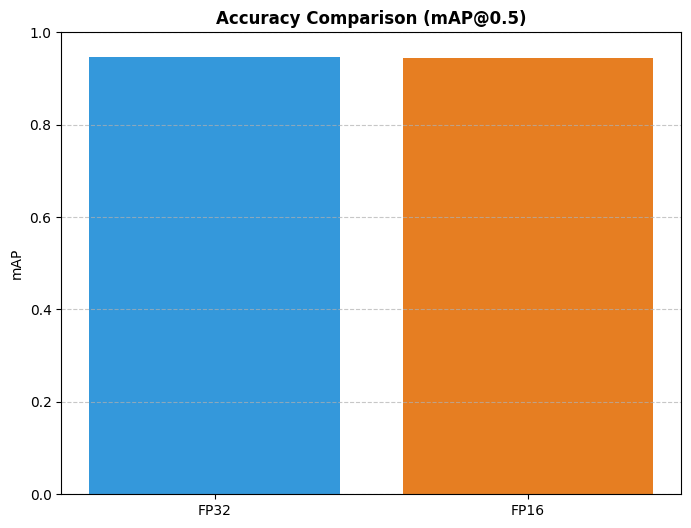

✅ Speed graph saved: /content/benchmark_results/speed_comparison.png


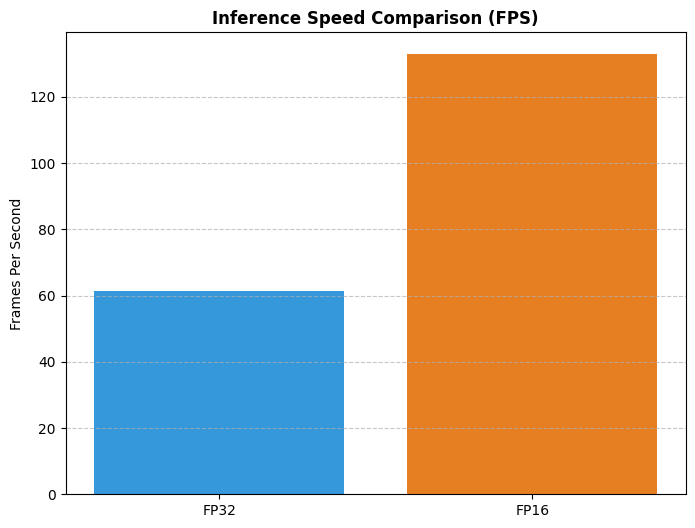

In [ ]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

results_file = Path('/content/benchmark_results/benchmark.json')
output_dir = Path('/content/benchmark_results')

if results_file.exists():
    with open(results_file, 'r') as f:
        results = json.load(f)

    labels = list(results.keys())
    map50 = [results[l]['mAP@0.5'] for l in labels]
    fps = [results[l]['fps'] for l in labels]
    colors = ['#3498db', '#e67e22', '#2ecc71']

    # 1. Save Accuracy Graph
    plt.figure(figsize=(8, 6))
    plt.bar(labels, map50, color=colors)
    plt.title('Accuracy Comparison (mAP@0.5)', fontweight='bold')
    plt.ylabel('mAP')
    plt.ylim(0, 1.0)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    acc_path = output_dir / 'accuracy_comparison.png'
    plt.savefig(acc_path, dpi=300, bbox_inches='tight')
    print(f'✅ Accuracy graph saved: {acc_path}')
    plt.show()

    # 2. Save Speed Graph
    plt.figure(figsize=(8, 6))
    plt.bar(labels, fps, color=colors)
    plt.title('Inference Speed Comparison (FPS)', fontweight='bold')
    plt.ylabel('Frames Per Second')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    speed_path = output_dir / 'speed_comparison.png'
    plt.savefig(speed_path, dpi=300, bbox_inches='tight')
    print(f'✅ Speed graph saved: {speed_path}')
    plt.show()

else:
    print(f'Error: {results_file} not found.')

In [ ]:
from google.colab import files
from pathlib import Path

# List of files to download
files_to_download = [
    '/content/benchmark_results/accuracy_comparison.png',
    '/content/benchmark_results/speed_comparison.png'
]

for file_path in files_to_download:
    if Path(file_path).exists():
        print(f'Downloading: {file_path}')
        files.download(file_path)
    else:
        print(f'File not found: {file_path}')

### Naito

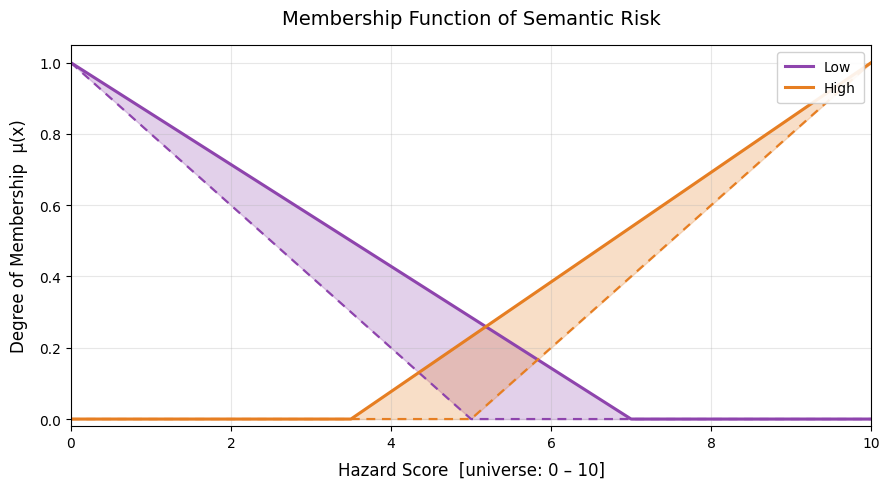

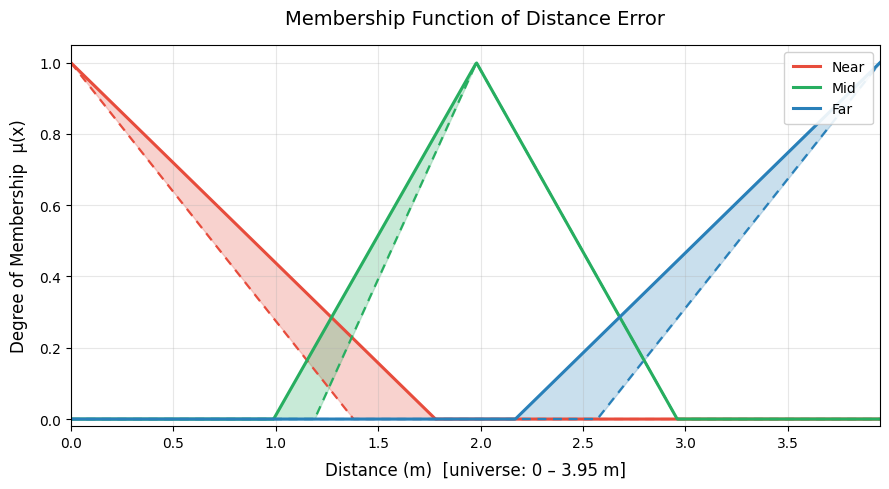

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  IT2 MEMBERSHIP FUNCTION PLOTTER  —  for Google Colab
#  Plots: (1) Semantic Risk classification   (2) Distance error
#  Each is Interval Type-2: Upper MF (solid) + Lower MF (dashed) + FOU (shaded)
#
#  HOW TO USE IN COLAB:
#    1. Open a new Colab notebook
#    2. Paste this whole script into ONE cell
#    3. Press Run. Two figures appear and also save as PNG.
# ═══════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
#  ## STYLE SETTINGS — change all visual options HERE ##
# ─────────────────────────────────────────────────────────────────────────────

# ## COLOURS — set the colour of each fuzzy set here ##
COLOR_LOW   = "#8E44AD"   # ## Low risk  / colour (purple)
COLOR_HIGH  = "#E67E22"   # ## High risk / colour (orange)
COLOR_NEAR  = "#E74C3C"   # ## Near distance colour (red)
COLOR_MID   = "#27AE60"   # ## Mid  distance colour (green)
COLOR_FAR   = "#2980B9"   # ## Far  distance colour (blue)

# ## FOU SHADING — transparency of the shaded uncertainty band (0=clear,1=solid)
FOU_ALPHA   = 0.25        # ## set FOU shading transparency here

# ## LINE STYLES ##
UMF_WIDTH   = 2.2         # ## Upper MF (solid) line thickness
LMF_WIDTH   = 1.6         # ## Lower MF (dashed) line thickness
LMF_DASH    = (4, 3)      # ## Lower MF dash pattern (dash length, gap length)

# ## BACKGROUND — 'white' for thesis, or '#0d1b3e' for dark (like the proposal)
BG_COLOR    = "white"     # ## set figure background colour here
GRID_ON     = True        # ## True to show grid, False to hide

# ## FONT SIZES ##
TITLE_SIZE  = 14          # ## title font size
LABEL_SIZE  = 12          # ## axis label font size
TICK_SIZE   = 10          # ## tick number font size
LEGEND_SIZE = 10          # ## legend font size

# ## SPACING — distance between title/legend/graph ##
TITLE_PAD   = 15          # ## gap between title and the graph (higher = more gap)
LABEL_PAD   = 8           # ## gap between axis labels and the axis
LEGEND_LOC  = "upper right"   # ## legend position: 'upper right', 'upper left',
                              #    'upper center', 'center right', etc.
LEGEND_ANCHOR = (1.0, 1.0)    # ## fine position (x, y); raise y above 1.0 to push
                              #    the legend ABOVE the graph, e.g. (0.5, 1.15)
LEGEND_NCOL = 1               # ## number of legend columns (2 makes it wider/shorter)
FIG_W, FIG_H = 9, 5           # ## figure width, height in inches


# ─────────────────────────────────────────────────────────────────────────────
#  Membership function primitives (do not need to edit)
# ─────────────────────────────────────────────────────────────────────────────

def trimf(x, a, b, c):
    """Triangular MF: 0 at a, peak 1 at b, 0 at c."""
    y = np.zeros_like(x)
    # rising edge a→b
    if b > a:
        m = (x > a) & (x <= b)
        y[m] = (x[m] - a) / (b - a)
    # falling edge b→c
    if c > b:
        m = (x > b) & (x < c)
        y[m] = (c - x[m]) / (c - b)
    y[x == b] = 1.0
    return y

def zmf(x, a, b):
    """Z-shaped MF (decreasing): 1 at x<=a, 0 at x>=b."""
    y = np.ones_like(x)
    m = (x > a) & (x < b)
    y[m] = 1.0 - (x[m] - a) / (b - a)
    y[x >= b] = 0.0
    return y

def smf(x, a, b):
    """S-shaped MF (increasing): 0 at x<=a, 1 at x>=b."""
    y = np.zeros_like(x)
    m = (x > a) & (x < b)
    y[m] = (x[m] - a) / (b - a)
    y[x >= b] = 1.0
    return y


# ─────────────────────────────────────────────────────────────────────────────
#  Helper to draw ONE IT2 set: UMF solid + LMF dashed + FOU shaded
# ─────────────────────────────────────────────────────────────────────────────

def draw_it2(ax, x, umf, lmf, color, label):
    # ## FOU shaded band between UMF and LMF ##
    ax.fill_between(x, lmf, umf, color=color, alpha=FOU_ALPHA)
    # ## Upper MF — solid line ##
    ax.plot(x, umf, color=color, linewidth=UMF_WIDTH, label=label)
    # ## Lower MF — dashed line (same colour) ##
    ax.plot(x, lmf, color=color, linewidth=LMF_WIDTH, dashes=LMF_DASH)


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 1 — SEMANTIC RISK CLASSIFICATION
#  ## Hazard score universe: 0–10 (this matches the proposal Figure 3.2) ##
# ═══════════════════════════════════════════════════════════════════════════

x_risk = np.linspace(0, 10, 1000)   # ## x-axis range for risk: 0 to 10

# ## RISK MEMBERSHIP VALUES — change breakpoints here to reshape the sets ##
# Low risk
low_umf  = zmf(x_risk, 0.0, 7.0)    # ## Low Upper MF: 1 at 0, falls to 0 at 7
low_lmf  = zmf(x_risk, 0.0, 5.0)    # ## Low Lower MF: 1 at 0, falls to 0 at 5
# High risk
high_umf = smf(x_risk, 3.5, 10.0)   # ## High Upper MF: 0 at 3.5, rises to 1 at 10
high_lmf = smf(x_risk, 5.0, 10.0)   # ## High Lower MF: 0 at 5,   rises to 1 at 10

fig1, ax1 = plt.subplots(figsize=(FIG_W, FIG_H))
fig1.patch.set_facecolor(BG_COLOR)     # ## figure background
ax1.set_facecolor(BG_COLOR)            # ## plot-area background

draw_it2(ax1, x_risk, low_umf,  low_lmf,  COLOR_LOW,  "Low")
draw_it2(ax1, x_risk, high_umf, high_lmf, COLOR_HIGH, "High")

# ## TITLE — text + spacing from graph (TITLE_PAD) ##
ax1.set_title("Membership Function of Semantic Risk",
              fontsize=TITLE_SIZE, pad=TITLE_PAD)
# ## AXIS LABELS — text + spacing from axis (LABEL_PAD) ##
ax1.set_xlabel("Hazard Score  [universe: 0 – 10]",
               fontsize=LABEL_SIZE, labelpad=LABEL_PAD)
ax1.set_ylabel("Degree of Membership  μ(x)",
               fontsize=LABEL_SIZE, labelpad=LABEL_PAD)

ax1.tick_params(labelsize=TICK_SIZE)   # ## tick number size
ax1.set_xlim(0, 10)                    # ## x range shown
ax1.set_ylim(-0.02, 1.05)              # ## y range shown (slight pad below 0)
if GRID_ON:
    ax1.grid(True, alpha=0.3)          # ## grid line transparency

# ## LEGEND — position, spacing, columns ##
ax1.legend(loc=LEGEND_LOC, bbox_to_anchor=LEGEND_ANCHOR,
           fontsize=LEGEND_SIZE, ncol=LEGEND_NCOL,
           framealpha=0.9,             # ## legend box transparency
           borderpad=0.6,              # ## padding inside legend box
           labelspacing=0.5)           # ## vertical gap between legend entries

fig1.tight_layout()                    # ## auto-fix spacing so nothing overlaps
fig1.savefig("risk_membership.png", dpi=200, bbox_inches="tight")  # ## saved PNG
plt.show()


# ═══════════════════════════════════════════════════════════════════════════
#  FIGURE 2 — DISTANCE ERROR
#  ## Distance universe RESCALED for 3x2m room: 0–3.95 m ##
#  ## To use the ORIGINAL proposal scale (0–10 m), see the commented block ##
# ═══════════════════════════════════════════════════════════════════════════

x_dist = np.linspace(0, 3.95, 1000)   # ## x-axis range for distance (room scale)

# ## DISTANCE MEMBERSHIP VALUES (rescaled for your room) — edit breakpoints here
near_umf = zmf(x_dist, 0.0, 1.78)
near_lmf = zmf(x_dist, 0.0, 1.38)
mid_umf  = trimf(x_dist, 0.99, 1.98, 2.96)
mid_lmf  = trimf(x_dist, 1.19, 1.98, 2.96)
far_umf  = smf(x_dist, 2.17, 3.95)
far_lmf  = smf(x_dist, 2.57, 3.95)

# ── ## ALTERNATIVE: original proposal scale 0–10m. Uncomment to use instead ##
# x_dist = np.linspace(0, 10, 1000)
# near_umf = zmf(x_dist, 0.0, 4.5);   near_lmf = zmf(x_dist, 0.0, 3.5)
# mid_umf  = trimf(x_dist, 2.5, 5.0, 7.5); mid_lmf = trimf(x_dist, 3.0, 5.0, 7.0)
# far_umf  = smf(x_dist, 5.5, 10.0);  far_lmf  = smf(x_dist, 6.5, 10.0)

fig2, ax2 = plt.subplots(figsize=(FIG_W, FIG_H))
fig2.patch.set_facecolor(BG_COLOR)
ax2.set_facecolor(BG_COLOR)

draw_it2(ax2, x_dist, near_umf, near_lmf, COLOR_NEAR, "Near")
draw_it2(ax2, x_dist, mid_umf,  mid_lmf,  COLOR_MID,  "Mid")
draw_it2(ax2, x_dist, far_umf,  far_lmf,  COLOR_FAR,  "Far")

ax2.set_title("Membership Function of Distance Error",
              fontsize=TITLE_SIZE, pad=TITLE_PAD)
ax2.set_xlabel("Distance (m)  [universe: 0 – 3.95 m]",
               fontsize=LABEL_SIZE, labelpad=LABEL_PAD)
ax2.set_ylabel("Degree of Membership  μ(x)",
               fontsize=LABEL_SIZE, labelpad=LABEL_PAD)

ax2.tick_params(labelsize=TICK_SIZE)
ax2.set_xlim(0, x_dist[-1])
ax2.set_ylim(-0.02, 1.05)
if GRID_ON:
    ax2.grid(True, alpha=0.3)

ax2.legend(loc=LEGEND_LOC, bbox_to_anchor=LEGEND_ANCHOR,
           fontsize=LEGEND_SIZE, ncol=LEGEND_NCOL,
           framealpha=0.9, borderpad=0.6, labelspacing=0.5)

fig2.tight_layout()
fig2.savefig("distance_membership.png", dpi=200, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════
#  ## To DOWNLOAD the PNGs from Colab, run this in a NEW cell: ##
#     from google.colab import files
#     files.download("risk_membership.png")
#     files.download("distance_membership.png")
# ═══════════════════════════════════════════════════════════════════════════